# BIOT 6900 Module 4: PDAC structure assessment
**Shreegowri M Bhojanna | ERBB4 and BRSK2**

I test whether the Module 3 candidates have credible small-molecule pockets. Clinical benefit in PDAC remains a separate question.

Run from this folder. Downloads from professor's file set are placed in `structures/` before running this notebook.

## Your settings (Step 1 · Choose two targets)

Pick two **protein-coding** targets from your Module 2 list, ideally **at least one with an experimental structure** (check the "Structure" section of the UniProt entry), each **shorter than 2,700 residues**.

For each target with a PDB structure, give the PDB ID and the chain to use. Use `None` if there is no experimental structure.

In [1]:
DISEASE = "pdac"
TARGETS = {"ERBB4": "Q15303", "BRSK2": "Q8IWQ3"}
TARGET_INFO = {
    "ERBB4": {"module2_rank": 4, "why": "High Module 3 small-molecule prior and a ligand-bound kinase structure."},
    "BRSK2": {"module2_rank": 12, "why": "Lower-confidence kinase candidate with published PDAC stress-response evidence."},
}
PDB = {"ERBB4": ("3BBT", "B"), "BRSK2": None}


In [2]:
import json, shutil, subprocess, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio.Align import PairwiseAligner
from IPython.display import display

RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

STRUCT = Path("structures"); STRUCT.mkdir(exist_ok=True)
assert set(TARGETS) == set(TARGET_INFO) == set(PDB), "TARGETS, TARGET_INFO and PDB must list the same genes"
if any(acc == "P00000" for acc in TARGETS.values()):
    raise ValueError("Set your two targets' UniProt accessions in the settings cell first.")

# ---------------- Helper functions (provided; from lab Part 2 and the demo) ----------------
def require(**kw):
    for name, val in kw.items():
        if val is Ellipsis:
            raise NotImplementedError(f"Complete the TODO above: `{name}` is still `...`")

def download(url, path):
    if path.exists() and path.stat().st_size > 0:
        return path
    req = urllib.request.Request(url, headers={"User-Agent": "BIOT6900-course-notebook"})
    with urllib.request.urlopen(req, timeout=60) as r:
        path.write_bytes(r.read())
    return path

def fetch_alphafold(acc):
    pdb_path, pae_path = STRUCT / f"AF-{acc}.pdb", STRUCT / f"AF-{acc}-pae.json"
    if pdb_path.exists() and pae_path.exists():
        return pdb_path, pae_path
    urls = []
    try:
        req = urllib.request.Request(f"https://alphafold.ebi.ac.uk/api/prediction/{acc}",
                                     headers={"User-Agent": "BIOT6900-course-notebook"})
        with urllib.request.urlopen(req, timeout=60) as r:
            entry = json.loads(r.read())[0]
        urls.append((entry["pdbUrl"], entry["paeDocUrl"]))
    except Exception as e:
        print(f"  API lookup failed for {acc} ({type(e).__name__}); trying direct file names")
    for v in ("v6", "v4"):
        base = f"https://alphafold.ebi.ac.uk/files/AF-{acc}-F1"
        urls.append((f"{base}-model_{v}.pdb", f"{base}-predicted_aligned_error_{v}.json"))
    for pu, eu in urls:
        try:
            download(pu, pdb_path); download(eu, pae_path)
            return pdb_path, pae_path
        except Exception:
            continue
    raise RuntimeError(f"Could not download {acc}: download by hand from https://alphafold.ebi.ac.uk/entry/{acc}")

def read_pdb(path, chain=None):
    rows = []
    for line in open(path):
        if line.startswith(("ATOM", "HETATM")):
            if line[16] not in (" ", "A") or (chain and line[21] != chain):
                continue
            rows.append({"record": line[:6].strip(), "atom": line[12:16].strip(), "resname": line[17:20].strip(),
                         "chain": line[21], "resnum": int(line[22:26]), "icode": line[26].strip(),
                         "x": float(line[30:38]), "y": float(line[38:46]), "z": float(line[46:54]),
                         "b": float(line[60:66]) if line[60:66].strip() else 0.0, "element": line[76:78].strip()})
        elif line.startswith("ENDMDL"):
            break
    return pd.DataFrame(rows)

def load_pae(path):
    js = json.load(open(path)); js = js[0] if isinstance(js, list) else js
    if "predicted_aligned_error" in js:
        return np.array(js["predicted_aligned_error"], dtype=float)
    n = int(max(js["residue1"])); return np.array(js["distance"], dtype=float).reshape(n, n)

def band(v):
    return "Very high" if v > 90 else "Confident" if v > 70 else "Low" if v > 50 else "Very low"
BAND_COLOUR = {"Very high": "#0053D6", "Confident": "#65CBF3", "Low": "#FFDB13", "Very low": "#FF7D45"}

def runs_below(values, resnums, cut=50, min_len=10):
    out, start = [], None
    for i, flag in enumerate(np.append(np.asarray(values) < cut, False)):
        if flag and start is None: start = i
        elif not flag and start is not None:
            if i - start >= min_len: out.append(f"{resnums[start]}-{resnums[i-1]}")
            start = None
    return ", ".join(out) or "none"

def find_domains(pae, plddt, pae_cut=8, min_size=20):
    ok = np.where(np.asarray(plddt) >= 70)[0]
    sub = pae[np.ix_(ok, ok)]; linked = (sub < pae_cut) & (sub.T < pae_cut)
    label, cur = -np.ones(len(ok), int), 0
    for s0 in range(len(ok)):
        if label[s0] >= 0: continue
        stack = [s0]; label[s0] = cur
        while stack:
            k = stack.pop()
            for m in np.where(linked[k] & (label < 0))[0]:
                label[m] = cur; stack.append(m)
        cur += 1
    out = [(ok[label == c].min() + 1, ok[label == c].max() + 1, int((label == c).sum())) for c in range(cur) if (label == c).sum() >= min_size]
    return pd.DataFrame(out, columns=["start", "end", "confident_residues"])

THREE = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E", "GLY": "G", "HIS": "H",
         "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P", "SER": "S", "THR": "T", "TRP": "W",
         "TYR": "Y", "VAL": "V"}
def ca_table(df):
    ca = df[(df.atom == "CA") & (df.record == "ATOM")].drop_duplicates(["resnum", "icode"]).reset_index(drop=True)
    ca["aa"] = ca.resname.map(THREE).fillna("X")
    return ca

def global_align(a, b):
    # Free end gaps handle experimental fragments; affine gaps handle missing loops.
    aligner = PairwiseAligner(mode="global", match_score=2, mismatch_score=-1,
                              open_gap_score=-10, extend_gap_score=-0.5)
    aligner.end_gap_score = 0
    alignment = aligner.align(a, b)[0]
    return [(i, j) for (a0, a1), (b0, b1) in zip(*alignment.aligned)
            for i, j in zip(range(a0, a1), range(b0, b1))]

def kabsch(P, Q):
    # Rotation R and shift t so that P @ R + t best matches Q, plus the RMSD
    Pc, Qc = P.mean(0), Q.mean(0)
    U, S_, Vt = np.linalg.svd((P - Pc).T @ (Q - Qc))
    d = np.sign(np.linalg.det(U @ Vt)); R = U @ np.diag([1, 1, d]) @ Vt
    rmsd = float(np.sqrt((((P - Pc) @ R - (Q - Qc)) ** 2).sum(1).mean()))
    return R, Qc - Pc @ R, rmsd

def run_fpocket(pdb_path):
    out_dir = pdb_path.parent / f"{pdb_path.stem}_out"
    if not (out_dir / f"{pdb_path.stem}_info.txt").exists():
        if shutil.which("fpocket") is None:
            raise RuntimeError("Install fpocket on Linux/Mac or use the supplied structures cache. See README.")
        print("Running fpocket:", pdb_path.name)
        subprocess.run(["fpocket", "-f", str(pdb_path)], check=True, capture_output=True, timeout=180)
    pockets, cur = [], None
    for line in (out_dir / f"{pdb_path.stem}_info.txt").read_text().splitlines():
        if line.startswith("Pocket"):
            cur = {"pocket": int(line.split()[1])}; pockets.append(cur)
        elif cur is not None and ":" in line:
            key, val = [s.strip() for s in line.split(":", 1)]
            if key in ("Druggability Score", "Volume"): cur[key] = float(val)
    for p in pockets:
        p["lining_residues"] = sorted(read_pdb(out_dir / "pockets" / f"pocket{p['pocket']}_atm.pdb").resnum.unique().tolist())
    return pd.DataFrame(pockets)
print("Settings and helpers loaded for:", ", ".join(f"{g} ({a})" for g, a in TARGETS.items()))

Settings and helpers loaded for: ERBB4 (Q15303), BRSK2 (Q8IWQ3)


## Step 2 · Download the AlphaFold model and PAE file

In [5]:
files, atoms, ca, pae = {}, {}, {}, {}
for gene, acc in TARGETS.items():
    files[gene] = fetch_alphafold(acc)
    atoms[gene] = read_pdb(files[gene][0])
    ca[gene] = ca_table(atoms[gene])
    pae[gene] = load_pae(files[gene][1])
    print(f"{gene} ({acc}): {len(ca[gene])} residues | PAE {pae[gene].shape}")
    assert list(ca[gene].resnum) == list(range(1, len(ca[gene]) + 1))
    assert pae[gene].shape == (len(ca[gene]), len(ca[gene]))

week2 = pd.read_csv("../data/pdac/targets_pdac.csv").dropna(subset=["score"]) #From module 2 - saved in the pdac data folder under the biot6900 main folder
week2["gene"] = week2.gene.str.strip().str.upper()
week2 = week2.sort_values("score", ascending=False).reset_index(drop=True)
week2["module2_rank"] = week2.index + 1
week3 = pd.read_csv("../data/pdac/targets_pdac_w3.csv") ##From module 3 - saved in the pdac data folder
selected = week2[week2.gene.isin(TARGETS)].merge(week3[["gene", "p_sm", "p_ab", "rank"]].rename(columns={"rank":"module3_rank"}), on="gene")
for g in TARGETS:
    assert selected.set_index("gene").loc[g, "module2_rank"] == TARGET_INFO[g]["module2_rank"]
display(selected[["gene", "module2_rank", "rna_effect", "prot_effect", "p_sm", "p_ab", "module3_rank"]])


ERBB4 (Q15303): 1308 residues | PAE (1308, 1308)
BRSK2 (Q8IWQ3): 736 residues | PAE (736, 736)


,gene,module2_rank,rna_effect,prot_effect,p_sm,p_ab,module3_rank
0,ERBB4,4,-2.565261,1.328604,0.702312,0.083039,2
1,BRSK2,12,-2.975515,-1.806538,0.267890,0.000119,12


## Step 3 · Read pLDDT

The plot is provided.  build the summary table: mean pLDDT, % above 90, % below 50, and the stretches of 10+ residues below 50 (use `runs_below`).

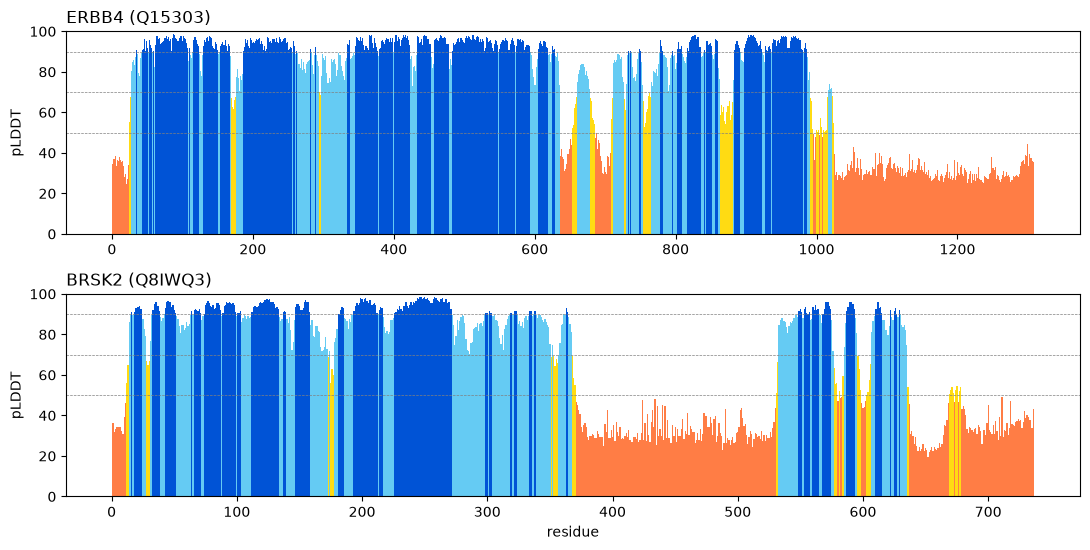

,gene,residues,mean_pLDDT,pct_above_90,pct_below_50,disordered_stretches
0,ERBB4,1308,73.12,43.81,26.91,"1-24, 637-652, 688-708, 1025-1308"
1,BRSK2,736,67.11,29.76,36.68,"1-11, 371-530, 637-668, 679-736"


In [6]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(11, 2.8 * len(TARGETS)), squeeze=False)
for ax, gene in zip(axes[:, 0], TARGETS):
    c = ca[gene]
    ax.bar(c.resnum, c.b, color=c.b.apply(band).map(BAND_COLOUR), width=1.0)
    for y in (50, 70, 90): ax.axhline(y, color="grey", lw=0.5, ls="--")
    ax.set_ylim(0, 100); ax.set_ylabel("pLDDT"); ax.set_title(f"{gene} ({TARGETS[gene]})", loc="left")
axes[-1, 0].set_xlabel("residue"); plt.tight_layout(); plt.savefig(RESULTS / "plddt.png", dpi=160); plt.show()

plddt_summary = pd.DataFrame([
    {"gene": g, "residues": len(c), "mean_pLDDT": c.b.mean(),
     "pct_above_90": 100 * (c.b > 90).mean(), "pct_below_50": 100 * (c.b < 50).mean(),
     "disordered_stretches": runs_below(c.b.values, c.resnum.values)}
    for g, c in ca.items()])
plddt_summary.to_csv(RESULTS / "plddt_summary.csv", index=False)
display(plddt_summary.round(2))


## Step 4 · Read PAE and find domains

Heatmaps are provided.  run `find_domains` for each target, and for any target with two or more domains compute the **mean PAE between the first two domains** (low = arrangement confident, high = uncertain).

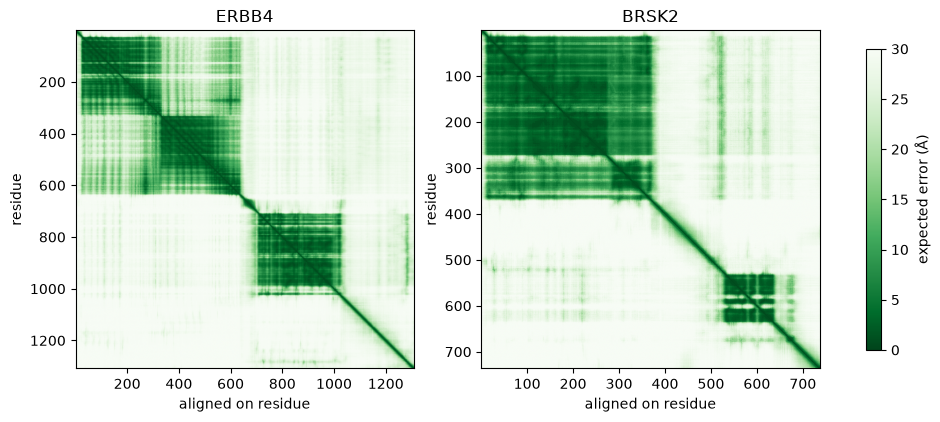

ERBB4: inter-domain PAE = 28.68 A


,start,end,confident_residues
0,27,635,601
1,711,1022,253


BRSK2: inter-domain PAE = 27.53 A


,start,end,confident_residues
0,14,367,342
1,533,635,84


In [7]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 4.6), squeeze=False)
for ax, gene in zip(axes[0], TARGETS):
    n = pae[gene].shape[0]
    im = ax.imshow(pae[gene], cmap="Greens_r", vmin=0, vmax=30, extent=[0.5, n + 0.5, n + 0.5, 0.5])
    ax.set_title(gene); ax.set_xlabel("aligned on residue"); ax.set_ylabel("residue")
plt.colorbar(im, ax=axes, label="expected error (Å)", shrink=0.85); plt.savefig(RESULTS / "pae.png", dpi=160); plt.show()

domains, inter_pae = {}, {}
for g in TARGETS:
    domains[g] = find_domains(pae[g], ca[g].b.values)
    inter_pae[g] = np.nan
    if len(domains[g]) >= 2:
        d1, d2 = domains[g].iloc[0], domains[g].iloc[1]
        i = np.arange(int(d1.start)-1, int(d1.end))
        j = np.arange(int(d2.start)-1, int(d2.end))
        inter_pae[g] = (pae[g][np.ix_(i,j)].mean() + pae[g][np.ix_(j,i)].mean()) / 2
    domains[g].to_csv(RESULTS / f"{g}_domains.csv", index=False)
    print(f"{g}: inter-domain PAE = {inter_pae[g]:.2f} A")
    display(domains[g])


**Interpretation.** These are connected confidence blocks (not exact biological domains). A block can contain gaps or several domains. Trust local pockets inside a block after checking their lining residues; do not trust the relative placement of blocks when inter-block PAE is high - in our example also we see such high inter-domain PAE.

ERBB4: extracellular 26-651, transmembrane 652-675, kinase 718-985; its long C-terminal tail is mostly low confidence. BRSK2: kinase 19-270 and UBA 297-339 lie within the first block; the long intervening region is poorly modelled. UniProt annotates disorder at 345-475, 493-513 and 681-736. Low pLDDT supports caution, not proof that a region is always disordered.

Sources: [ERBB4](https://www.uniprot.org/uniprotkb/Q15303/entry), [BRSK2](https://www.uniprot.org/uniprotkb/Q8IWQ3/entry).

## Step 5 · Compare with an experimental structure

For each target with a PDB entry: pair residues **by sequence alignment** (numbering often differs), superimpose on **identical, confident** pairs (pLDDT ≥ 70), and report the RMSD. If the target has two or more domains with high PAE between them, also report RMSD **per domain**.

**Structure choice:** 3BBT chain B (2.80 A) supplies the lapatinib-bound kinase site. I also compare 2AHX chain A (2.40 A; residues 26-641) below for broad extracellular coverage. 3U9U extends to 650 but is lower resolution (3.42 A). No single entry covers the intact receptor. 

BRSK2 has no PDB cross-reference in the checked UniProt record.

The original linear-gap alignment gave spurious fragment-end matches. I use sequence alignment with affine gaps and free terminal gaps, and exclude mismatches from fitting. This yields the expected experimental sequence coverage without matching by residue number.


In [9]:
comparison, deviation, exp_map = {}, {}, {}
for gene, entry in PDB.items():
    if entry is None:
        print(f"{gene}: no experimental structure; assess on confidence alone.")
        comparison[gene] = {"pdb_id": "none", "rmsd_confident": np.nan, "pairs_used": 0}
        continue
    pdb_id, chain = entry
    xt = read_pdb(download(f"https://files.rcsb.org/download/{pdb_id}.pdb", STRUCT / f"{pdb_id}.pdb"), chain=chain)
    xca, aca = ca_table(xt), ca[gene]
    pairs = global_align("".join(aca.aa), "".join(xca.aa))
    exp_map[gene] = {(xca.resnum[j], xca.icode[j]): aca.resnum[i] for i, j in pairs if aca.aa[i] == xca.aa[j]}   # identical pairs only
    A, X = aca[["x", "y", "z"]].to_numpy(), xca[["x", "y", "z"]].to_numpy()

    use = [(i, j) for i, j in pairs if aca.aa[i] == xca.aa[j] and aca.b[i] >= 70]
    assert len(use) >= 10
    R, t, rmsd = kabsch(A[[i for i, _ in use]], X[[j for _, j in use]])
    mapping = pd.DataFrame([{"pdb_residue": xca.resnum[j], "icode": xca.icode[j],
                            "uniprot_residue": aca.resnum[i], "identical": aca.aa[i] == xca.aa[j]}
                           for i, j in pairs])
    mapping.to_csv(RESULTS / f"{gene}_{pdb_id}_mapping.csv", index=False)
    moved = A @ R + t
    deviation[gene] = pd.Series({aca.resnum[i]: float(np.linalg.norm(moved[i] - X[j])) for i, j in use})
    comparison[gene] = {"pdb_id": pdb_id, "rmsd_confident": rmsd, "pairs_used": len(use)}
    print(f"{gene} vs {pdb_id} chain {chain}: {len(pairs)} aligned pairs, {len(use)} identical and confident; RMSD {rmsd:.2f} Å")

    # Per-domain RMSD when the arrangement between domains is uncertain
    if len(domains[gene]) >= 2 and inter_pae[gene] > 10:
        for k, d in domains[gene].iterrows():
            sub = [(i, j) for i, j in use if d.start <= aca.resnum[i] <= d.end]
            if len(sub) >= 10:
                print(f"   domain {k + 1} ({d.start}-{d.end}): RMSD {kabsch(A[[i for i, _ in sub]], X[[j for _, j in sub]])[2]:.2f} Å over {len(sub)} residues")
for g, d in deviation.items():
    d.rename("deviation_A").rename_axis("uniprot_residue").to_csv(RESULTS / f"{g}_deviation.csv")
pd.DataFrame(comparison).T.to_csv(RESULTS / "experimental_comparison.csv")


ERBB4 vs 3BBT chain B: 274 aligned pairs, 245 identical and confident; RMSD 1.38 Å
   domain 2 (711-1022): RMSD 1.38 Å over 245 residues
BRSK2: no experimental structure; assess on confidence alone.


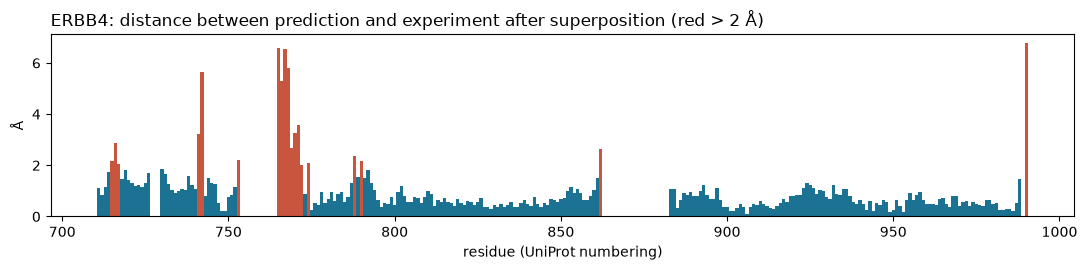

ERBB4: residues that differ most: 990 (6.8 Å), 765 (6.6 Å), 767 (6.6 Å), 768 (5.8 Å), 742 (5.6 Å), 766 (5.3 Å)


In [10]:
for gene, dev in deviation.items():
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.bar(dev.index, dev.values, color=["#C8553D" if d > 2 else "#1C7293" for d in dev.values], width=1.0)
    ax.set_title(f"{gene}: distance between prediction and experiment after superposition (red > 2 Å)", loc="left")
    ax.set_xlabel("residue (UniProt numbering)"); ax.set_ylabel("Å"); plt.tight_layout(); plt.savefig(RESULTS / f"{gene}_deviation.png", dpi=160); plt.show()
    print(f"{gene}: residues that differ most:", ", ".join(f"{r} ({v:.1f} Å)" for r, v in dev.nlargest(6).items()))

2AHX A: 596 identical confident pairs; RMSD 2.08 A
Mismatch excluded: [(549, 'G', 'D')]


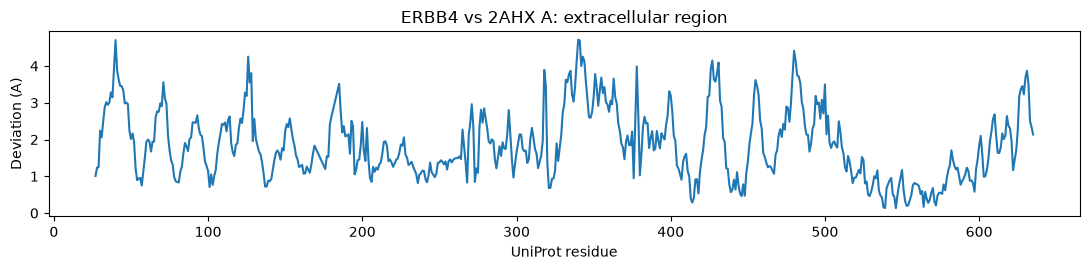

In [11]:
# Broader experimental coverage: fit ERBB4 extracellular region separately.
x = ca_table(read_pdb(download("https://files.rcsb.org/download/2AHX.pdb", STRUCT / "2AHX.pdb"), "A"))
a = ca["ERBB4"]
pairs = global_align("".join(a.aa), "".join(x.aa))
use = [(i,j) for i,j in pairs if a.aa[i] == x.aa[j] and a.b[i] >= 70]
A, X = a[["x","y","z"]].values, x[["x","y","z"]].values
R, t, ecto_rmsd = kabsch(A[[i for i,j in use]], X[[j for i,j in use]])
ecto_dev = pd.Series({a.resnum[i]: np.linalg.norm(A[i] @ R + t - X[j]) for i,j in use})
print(f"2AHX A: {len(use)} identical confident pairs; RMSD {ecto_rmsd:.2f} A")
print("Mismatch excluded:", [(int(a.resnum[i]), a.aa[i], x.aa[j]) for i,j in pairs if a.aa[i] != x.aa[j]])
ecto_dev.rename("deviation_A").rename_axis("uniprot_residue").to_csv(RESULTS / "ERBB4_2AHX_deviation.csv")
pd.DataFrame([{"gene":"ERBB4", "pdb_id":"2AHX", "chain":"A", "pairs_used":len(use),
               "rmsd_confident":ecto_rmsd}]).to_csv(RESULTS / "extra_experimental_comparison.csv", index=False)
fig, ax = plt.subplots(figsize=(11,2.8))
ax.plot(ecto_dev.index, ecto_dev.values); ax.set(xlabel="UniProt residue", ylabel="Deviation (A)", title="ERBB4 vs 2AHX A: extracellular region")
plt.tight_layout(); plt.savefig(RESULTS / "ERBB4_2AHX_deviation.png", dpi=160); plt.show()


## Step 6 · Detect and filter pockets

 for each pocket, compute the mean pLDDT of the lining residues and the mean PAE among them, then apply the rules: **reject** if mean pLDDT < 70; **suspect** if PAE among the lining residues > 10 Å; otherwise **keep**. Show the top five by druggability score. Every pocket is kept (with its **rank** by score) for the ligand-site check below.

In [12]:
if shutil.which("fpocket") is None:
    raise RuntimeError("fpocket not found. Mac/Linux: conda install -c conda-forge fpocket, then restart the kernel. "
                       "Windows: run this notebook on the Explorer cluster.") 

top_pockets, all_pockets = {}, {}
for gene in TARGETS:
    pk = run_fpocket(files[gene][0])
    plddt = ca[gene].set_index("resnum").b
    pk["mean_pLDDT"] = pk.lining_residues.apply(lambda r: plddt.loc[r].mean())
    pk["PAE_within"] = pk.lining_residues.apply(
        lambda r: pae[gene][np.ix_(np.array(r)-1, np.array(r)-1)].mean())
    pk["verdict"] = np.where(pk.mean_pLDDT < 70, "reject",
                             np.where(pk.PAE_within > 10, "suspect", "keep"))
    pk["rank"] = pk["Druggability Score"].rank(ascending=False, method="first").astype(int)
    pk["pct_lining_below_70"] = pk.lining_residues.apply(lambda r: 100*(plddt.loc[r] < 70).mean())
    pk["span"] = pk.lining_residues.apply(lambda r: f"{min(r)}-{max(r)}")
    all_pockets[gene] = pk
    top_pockets[gene] = pk.sort_values("rank").head(5)
    pk.to_csv(RESULTS / f"{gene}_all_pockets.csv", index=False)
    top_pockets[gene].to_csv(RESULTS / f"{gene}_top5_pockets.csv", index=False)
    print(gene, "all pockets:", pk.verdict.value_counts().to_dict())
    display(top_pockets[gene].drop(columns="lining_residues").round(3))


RuntimeError: Install fpocket on Linux/Mac or use the supplied structures cache. See README.

### Ligand-site check *(provided)*

**If your experimental structure has a ligand bound,** the next cell takes **each** bound ligand in turn, finds the protein residues within 4.5 Å of it, converts them to UniProt numbering using your Step 5 alignment, and searches **every** pocket, not just the top five. For each ligand it reports how much of the site your best kept pocket covers, and which pocket covers it best, with that pocket's rank, score and verdict.

**In your report:** is your best **kept** pocket where the ligand sits? If there are several copies of a ligand, which one is in the functional site? If not, which pocket is, how does it rank, and why might fpocket score a real binding site low? (Large, open or polar sites, such as protease clefts, often score poorly.)

*Not counted as ligands:* water, metal ions, common crystallization additives (sulfate, glycerol and similar), and peptide or nucleic-acid partners deposited as a separate protein or DNA chain.

In [29]:
print("Run from linux system or cluster\n\n")
IGNORE_HET = {"HOH", "WAT", "DOD", "SO4", "PO4", "GOL", "EDO", "PEG", "PG4", "PGE", "1PE", "ACT", "FMT", "DMS",
              "MPD", "BME", "TRS", "EPE", "MES", "IMD", "CL", "NA", "K", "MG", "CA", "ZN", "MN", "FE", "CU", "CO",
              "NI", "CD", "HG", "IOD", "BR", "NO3", "NH4", "SCN", "UNX"}

def ligand_sites(pdb_path, chain, cutoff=4.5, min_atoms=6):
    """For each small-molecule ligand touching `chain`: the (resnum, icode) of chain residues within `cutoff` Å."""
    at = read_pdb(pdb_path)
    het = at[(at.record == "HETATM") & ~at.resname.isin(IGNORE_HET)]
    het = het[het.groupby(["chain", "resname", "resnum"]).x.transform("size") >= min_atoms]   # drop ions / tiny additives
    prot = at[(at.record == "ATOM") & (at.chain == chain)]
    sites = {}
    for (c, name, num), lig in het.groupby(["chain", "resname", "resnum"]):
        d = np.linalg.norm(prot[["x", "y", "z"]].to_numpy()[:, None] - lig[["x", "y", "z"]].to_numpy()[None], axis=2)
        near = (d < cutoff).any(1)
        if near.any():
            sites[f"{name} {c}{num}"] = set(zip(prot.resnum[near], prot.icode[near]))
    return sites
"""
ligand_pockets = {}
for gene, entry in PDB.items():
    if entry is None:
        print(f"{gene}: no experimental structure, so no ligand-site check.\n"); continue
    pdb_id, chain = entry
    sites = ligand_sites(STRUCT / f"{pdb_id}.pdb", chain)
    if not sites:
        print(f"{gene}: {pdb_id} chain {chain} has no bound small-molecule ligand to check against.\n"); continue
    pk = all_pockets[gene]
    kept = pk[pk.verdict == "keep"].sort_values("Druggability Score", ascending=False)
    best = kept.iloc[0] if len(kept) else None
    rows = []
    for lig, contacts in sites.items():
        site = sorted({exp_map[gene][k] for k in contacts if k in exp_map[gene]})   # UniProt numbering
        if not site:
            print(f"  {lig}: its contact residues are not in the aligned region; skipped"); continue
        cover = pk.lining_residues.apply(lambda r: len(set(r) & set(site)) / len(site))
        top = pk.loc[cover.idxmax()]
        rows.append({"ligand": lig, "site_residues": len(site),
                     "best_kept_pocket_covers": round(float(cover[best.name]), 2) if best is not None else np.nan,
                     "site_pocket": int(top.pocket), "site_pocket_rank": int(top["rank"]),
                     "site_pocket_score": round(top["Druggability Score"], 3), "site_pocket_verdict": top.verdict,
                     "site_pocket_covers": round(float(cover.max()), 2), "residues": ", ".join(map(str, site))})
    ligand_pockets[gene] = pd.DataFrame(rows)
    print(f"{gene} vs {pdb_id} chain {chain}  |  best kept pocket: "
          + (f"{int(best.pocket)} (score {best['Druggability Score']:.3f}, rank {int(best['rank'])})" if best is not None else "none"))
    print(ligand_pockets[gene].drop(columns="residues").to_string(index=False))
    for r in rows:
        print(f"  {r['ligand']} site (UniProt numbering): {r['residues']}")
    print()


for g, table in ligand_pockets.items():
    table.to_csv(RESULTS / f"{g}_ligand_sites.csv", index=False)

"""

Run from linux system or cluster




'\nligand_pockets = {}\nfor gene, entry in PDB.items():\n    if entry is None:\n        print(f"{gene}: no experimental structure, so no ligand-site check.\n"); continue\n    pdb_id, chain = entry\n    sites = ligand_sites(STRUCT / f"{pdb_id}.pdb", chain)\n    if not sites:\n        print(f"{gene}: {pdb_id} chain {chain} has no bound small-molecule ligand to check against.\n"); continue\n    pk = all_pockets[gene]\n    kept = pk[pk.verdict == "keep"].sort_values("Druggability Score", ascending=False)\n    best = kept.iloc[0] if len(kept) else None\n    rows = []\n    for lig, contacts in sites.items():\n        site = sorted({exp_map[gene][k] for k in contacts if k in exp_map[gene]})   # UniProt numbering\n        if not site:\n            print(f"  {lig}: its contact residues are not in the aligned region; skipped"); continue\n        cover = pk.lining_residues.apply(lambda r: len(set(r) & set(site)) / len(site))\n        top = pk.loc[cover.idxmax()]\n        rows.append({"ligand": li

## Step 7 · Make a druggability call and export the summary

Choose one call per target: **"Structure supports a small-molecule pocket"**, **"Possible but uncertain"**, or **"No confident pocket: consider another modality"**. Justify it in your report.

In [23]:
print("Run from linux system or cluster\n\n")
"""
CALLS = {"ERBB4": "Structure supports a small-molecule pocket",
         "BRSK2": "Possible but uncertain"}
assert set(CALLS) == set(TARGETS), "Give a call for every target"

rows = []
for g, acc in TARGETS.items():
    kept = all_pockets[g][all_pockets[g].verdict == "keep"]
    rows.append({"gene": g, "uniprot": acc, "module2_rank": TARGET_INFO[g]["module2_rank"],
                 "mean_pLDDT": plddt_summary.set_index("gene").loc[g, "mean_pLDDT"],
                 "pct_below_50": plddt_summary.set_index("gene").loc[g, "pct_below_50"],
                 "n_domains": len(domains[g]), "inter_domain_PAE": inter_pae[g],
                 "pdb_id": comparison[g]["pdb_id"], "rmsd_confident": comparison[g]["rmsd_confident"],
                 "best_pocket_score": round(kept["Druggability Score"].max(), 3) if len(kept) else np.nan,
                 "best_pocket_verdict": "keep" if len(kept) else top_pockets[g].verdict.iloc[0],
                 "druggability_call": CALLS[g]})
summary = pd.DataFrame(rows)
summary = summary.merge(week3[["gene", "p_sm", "p_ab", "rank"]].rename(columns={"rank":"module3_rank"}), on="gene")
out_file = f"structure_assessment_{DISEASE}.csv"
summary.to_csv(out_file, index=False)
print("Wrote", out_file)
display(summary)
"""

Run from linux system or cluster




'\nCALLS = {"ERBB4": "Structure supports a small-molecule pocket",\n         "BRSK2": "Possible but uncertain"}\nassert set(CALLS) == set(TARGETS), "Give a call for every target"\n\nrows = []\nfor g, acc in TARGETS.items():\n    kept = all_pockets[g][all_pockets[g].verdict == "keep"]\n    rows.append({"gene": g, "uniprot": acc, "module2_rank": TARGET_INFO[g]["module2_rank"],\n                 "mean_pLDDT": plddt_summary.set_index("gene").loc[g, "mean_pLDDT"],\n                 "pct_below_50": plddt_summary.set_index("gene").loc[g, "pct_below_50"],\n                 "n_domains": len(domains[g]), "inter_domain_PAE": inter_pae[g],\n                 "pdb_id": comparison[g]["pdb_id"], "rmsd_confident": comparison[g]["rmsd_confident"],\n                 "best_pocket_score": round(kept["Druggability Score"].max(), 3) if len(kept) else np.nan,\n                 "best_pocket_verdict": "keep" if len(kept) else top_pockets[g].verdict.iloc[0],\n                 "druggability_call": CALLS[g]})\nsum

## Step 8 · Anchor check: p53

From your **lab Part 2** results, write one short paragraph in your report: the p53 RMSD to 1TUP over confident residues, which hotspots are zinc ligands and which touch DNA, and what that says about your Module 3 variant scores. No code needed here.

## Step 9 · Report (3–4 pages, the 40%)

Answer the five questions on the assignment sheet (confidence, validation, druggability, integration, limits), using the tables and plots above. Submit the notebook, `structure_assessment_<disease>.csv`, your report (PDF) and a README, and add `structures/` to `.gitignore`.

In [15]:
# Repeat the Part 2 p53 anchor with the supplied structures.
p53_file, _ = fetch_alphafold("P04637")
a53 = ca_table(read_pdb(p53_file))
x53 = read_pdb(download("https://files.rcsb.org/download/1TUP.pdb", STRUCT / "1TUP.pdb"))
b53 = x53[(x53.chain == "B") & (x53.record == "ATOM")]
c53 = ca_table(b53)
pairs53 = global_align("".join(a53.aa), "".join(c53.aa))
use53 = [(i,j) for i,j in pairs53 if a53.aa[i] == c53.aa[j] and a53.b[i] >= 70]
_, _, rmsd53 = kabsch(a53[["x","y","z"]].values[[i for i,j in use53]],
                     c53[["x","y","z"]].values[[j for i,j in use53]])
print(f"p53 vs 1TUP B: {len(use53)} confident pairs; RMSD {rmsd53:.3f} A")
zn = x53[x53.resname == "ZN"]
dna = x53[x53.resname.isin(["DA","DC","DG","DT","A","C","G","T"])]
def min_dist(a, b):
    return np.linalg.norm(a[["x","y","z"]].values[:,None] - b[["x","y","z"]].values[None], axis=2).min()
rows53 = []
for r in [175,176,179,220,238,242,245,248,249,273,282]:
    side = b53[(b53.resnum == r) & ~b53.atom.isin(["N","C","O"])]
    dz, dd = min_dist(side,zn), min_dist(side,dna)
    role = "zinc ligand" if dz < 3 else "DNA contact" if dd < 4.5 else "near DNA" if dd < 8 else "structural / other"
    rows53.append({"residue":r, "aa":side.resname.iloc[0], "zinc_distance_A":dz, "DNA_distance_A":dd, "role":role})
hotspots = pd.DataFrame(rows53)
hotspots.to_csv(RESULTS / "p53_hotspots.csv", index=False)
(RESULTS / "p53_rmsd.json").write_text(json.dumps({"pdb":"1TUP", "chain":"B", "n":len(use53), "rmsd":rmsd53}))
display(hotspots.round(2))


p53 vs 1TUP B: 192 confident pairs; RMSD 0.676 A


,residue,aa,zinc_distance_A,DNA_distance_A,role
0,175,ARG,5.30,13.17,structural / other
1,176,CYS,2.33,10.79,zinc ligand
2,179,HIS,2.06,8.16,zinc ligand
3,220,TYR,29.03,29.83,structural / other
4,238,CYS,2.21,8.65,zinc ligand
5,242,CYS,2.24,7.24,zinc ligand
6,245,GLY,6.13,11.11,structural / other
7,248,ARG,10.60,3.39,DNA contact
8,249,ARG,11.35,7.24,near DNA
9,273,ARG,12.92,2.54,DNA contact


### My calls
- **ERBB4: structure supports a small-molecule pocket.** Kinase RMSD 1.38 A (245 pairs); pocket 93 scores 0.894 and covers 14/19 lapatinib-contact residues. It passes the course rules, but includes low-confidence residue 1237. Mean confidence can hide weak lining residues. Extracellular RMSD is 2.08 A; this does not validate its placement relative to the kinase - Not sure if having such low score on C-terminus which is farther away from the kinase domain is sufficient to say the kinase domain is tractable/druggable - need some assistance/collaboration with structural biologist.
- **BRSK2: possible but uncertain.** There are 30 kept pockets, but the highest score is only 0.014. No mapped experimental structure was found. This model alone does not support a strong druggability claim. Published cellular inhibitor evidence makes it worth testing, without proving PDAC benefit or inhibitor selectivity.
- **Integration:** ERBB4 moves from Module 2 rank 4 to Module 3 rank 2; BRSK2 remains 12. Their small-molecule priors were 0.702 and 0.267. I retain ERBB4 for pocket work and BRSK2 as a conditional candidate. RNA/protein direction and tumour dependence must be resolved before choosing inhibition.
- **p53 anchor:** RMSD to 1TUP B is 0.676 A over 192 confident pairs. C176/H179/C238/C242 coordinate zinc; R248/R273 contact DNA. R175 and G245 are not direct zinc ligands or DNA contacts under these cutoffs. Negative variant scores can reflect disrupted packing, metal coordination or DNA binding; they do not specify mechanism. The wild-type structure cannot establish the Y220C mutant pocket.

**Sources:** [3BBT](https://www.rcsb.org/structure/3BBT), [2AHX](https://www.rcsb.org/structure/2AHX), [1TUP](https://www.rcsb.org/structure/1TUP), [PDAC stress study](https://doi.org/10.18632/oncotarget.17965), [BRSK2 inhibitor study](https://doi.org/10.1038/s41598-020-72869-9). See the report for limitations and next steps.

In [14]:
import hashlib, platform, Bio
tracked = list(STRUCT.glob("*.pdb")) + list(STRUCT.glob("*-pae.json"))
tracked += list(STRUCT.glob("*_out/*_info.txt"))
tracked += [Path("../data/pdac/targets_pdac.csv"), Path("../data/pdac/targets_pdac_w3.csv")]
run_info = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "biopython": Bio.__version__, "fpocket_source_release": "4.2.3",
            "pocket_rules": "reject mean pLDDT <70; suspect mean PAE >10; otherwise keep",
            "sha256": {str(f): hashlib.sha256(f.read_bytes()).hexdigest() for f in tracked}}
(RESULTS / "run_info.json").write_text(json.dumps(run_info, indent=2))
print("Saved summary and analysis tables in results/.")


Saved summary and analysis tables in results/.
